In [1]:
# import necesasry libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Set style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [2]:
# Load Dataset
!curl -L -o jigsaw-toxic-comment-classification-challenge.zip https://www.kaggle.com/api/v1/datasets/download/julian3833/jigsaw-toxic-comment-classification-challenge
!unzip -o jigsaw-toxic-comment-classification-challenge.zip

df = pd.read_csv("train.csv")
print("Dataset Shape:", df.shape)
df.head(10)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 53.3M  100 53.3M    0     0  10.4M      0  0:00:05  0:00:05 --:--:-- 12.9M
Archive:  jigsaw-toxic-comment-classification-challenge.zip
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: test_labels.csv         
  inflating: train.csv               
Dataset Shape: (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0


In [3]:
# EDA (Exploratory Data analysis)
# Dataset info
df.info()

# Missing values
print(df.isnull().sum())

# Class distribution (multi-label, so we check sums per column)
label_cols = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]
df[label_cols].sum().sort_values(ascending=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


,0
toxic,15294
obscene,8449
insult,7877
severe_toxic,1595
identity_hate,1405
threat,478


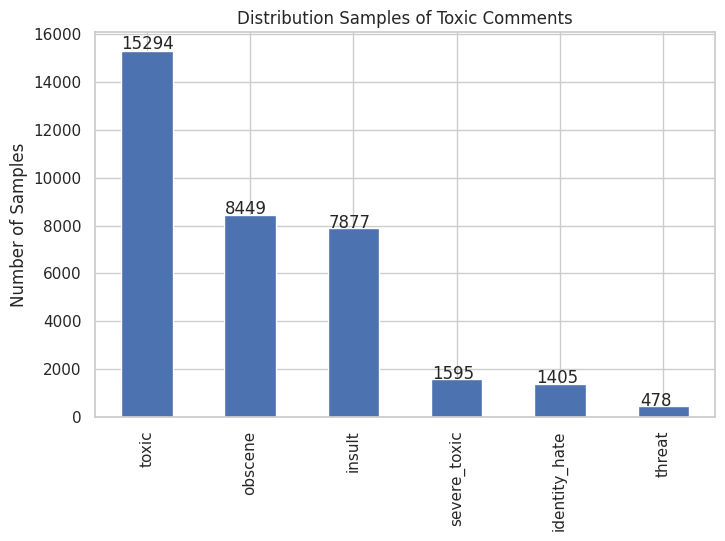

In [4]:
# Distribution Plot
plt.figure(figsize=(8,5))
ax = df[label_cols].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Distribution Samples of Toxic Comments")
plt.ylabel("Number of Samples")

# Add labels to the bars
for p in ax.patches:
    ax.annotate(str(p.get_height()), (p.get_x() * 1.005, p.get_height() * 1.005))
plt.show()

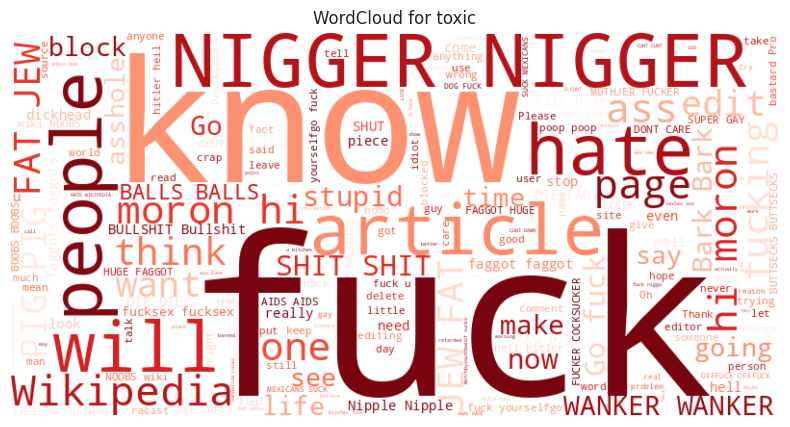

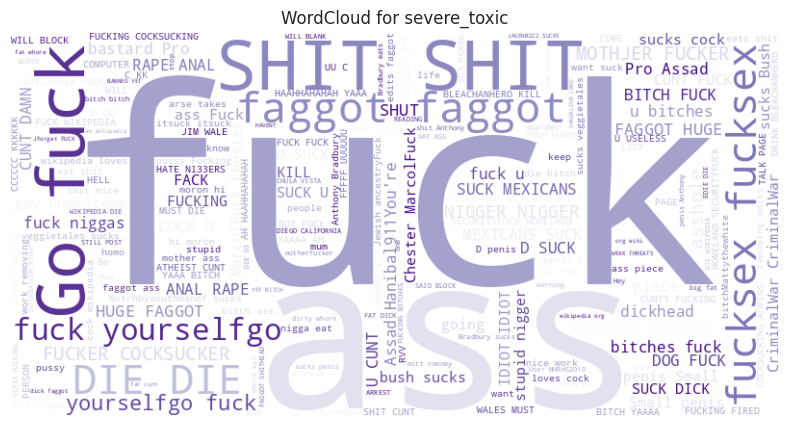

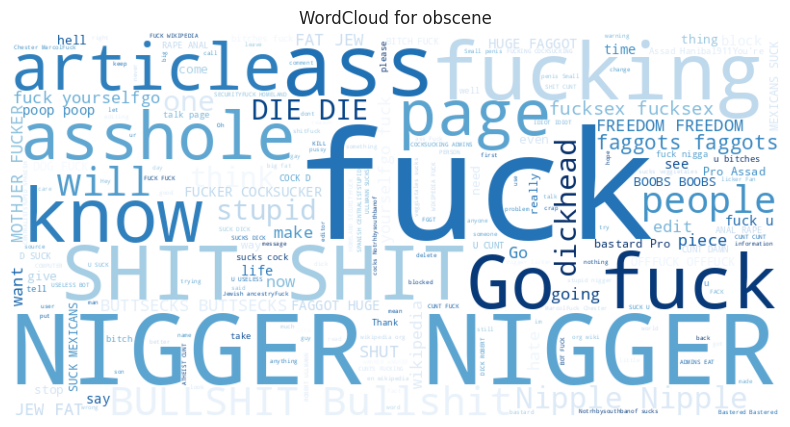

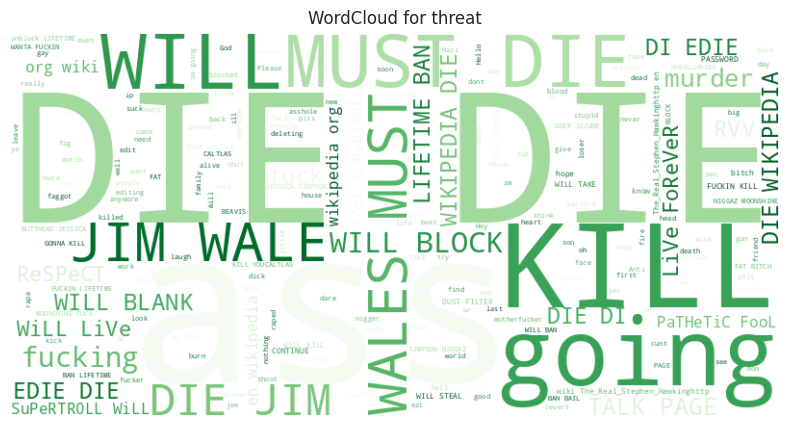

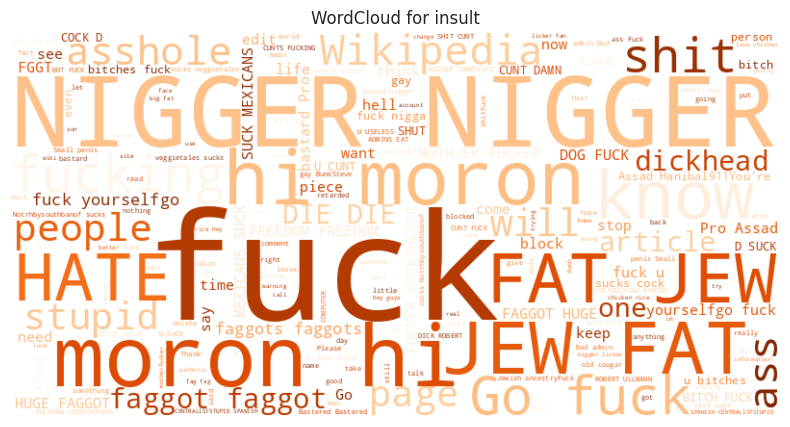

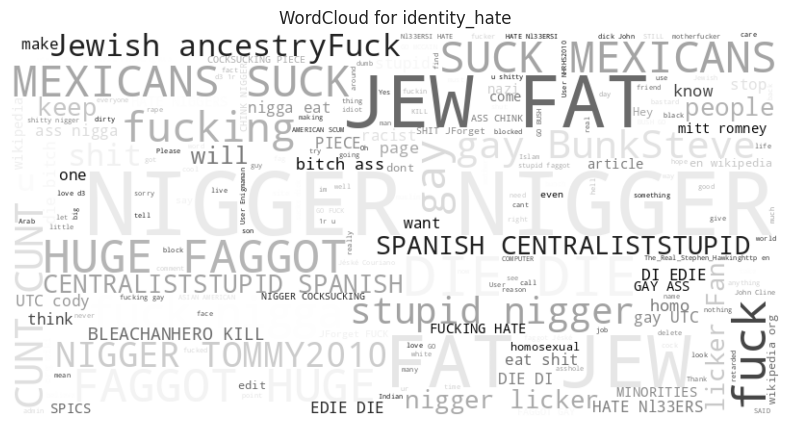

In [5]:
# Word Cloud for each types
def plot_wordcloud(label, color):
    """
    Generates and displays a word cloud for comments belonging to a specific toxicity label.

    Args:
        label (str): The name of the toxicity label (e.g., 'toxic', 'severe_toxic').
        color (str): The colormap to use for the word cloud (e.g., 'Reds', 'Blues').
    """
    text = " ".join(df[df[label]==1]["comment_text"].astype(str))
    wc = WordCloud(width=800, height=400, background_color="white", colormap=color).generate(text)
    plt.figure(figsize=(10,5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud for {label}")
    plt.show()

# Generate and display word clouds for each toxicity label
for label, color in zip(label_cols, ["Reds","Purples","Blues","Greens","Oranges","Greys"]):
    plot_wordcloud(label, color)

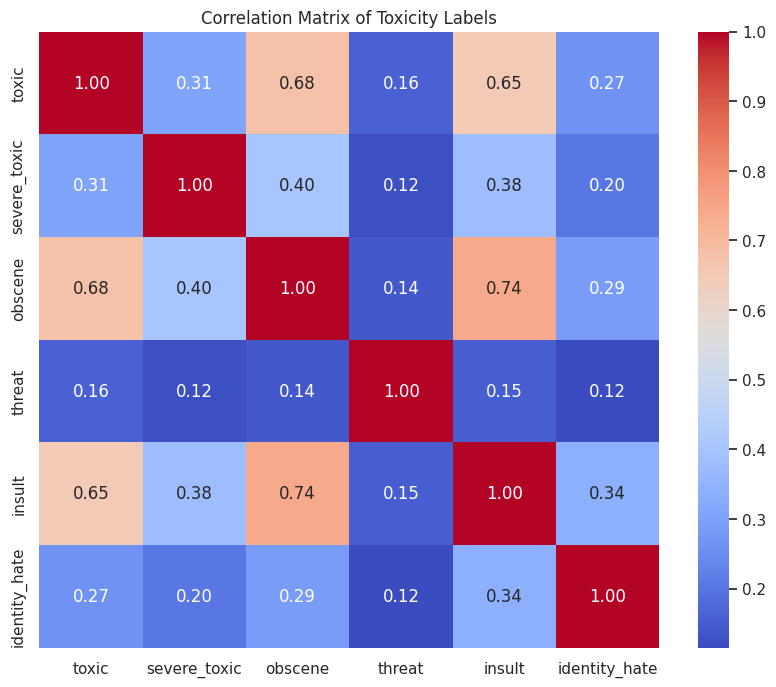

In [6]:
# Correlation matrix for labels
# Calculate the correlation matrix for toxicity labels
plt.figure(figsize=(10, 8))
sns.heatmap(df[label_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Toxicity Labels")
plt.show()

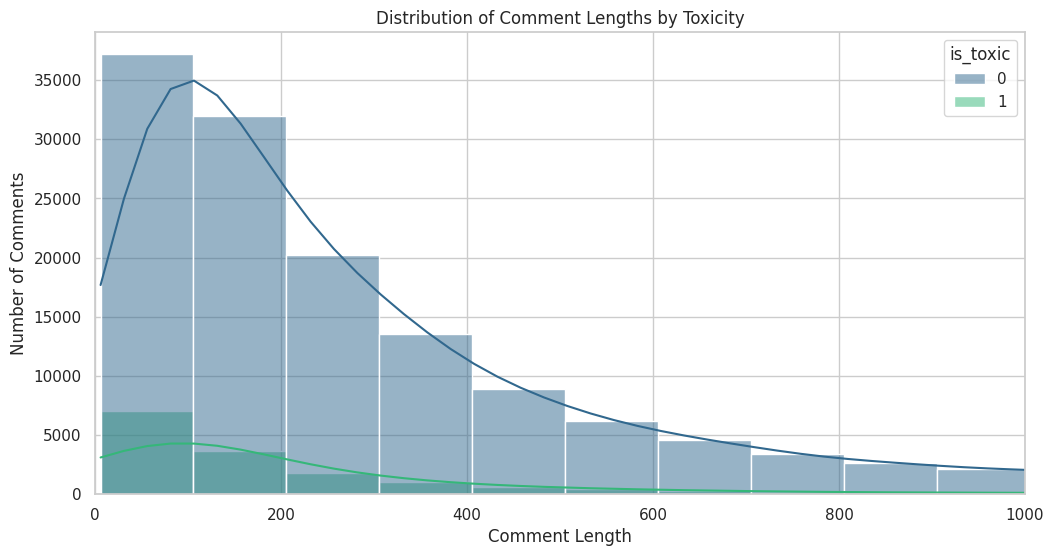

In [7]:
# Comment length analysis
# Add a column for comment length
df["comment_length"] = df["comment_text"].apply(len)

# Create a 'toxic' indicator (1 if any label is 1, 0 otherwise)
df["is_toxic"] = df[label_cols].any(axis=1).astype(int)

# Plot the distribution of comment lengths for toxic vs. non-toxic comments
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x="comment_length", hue="is_toxic", bins=50, kde=True, palette="viridis")
plt.title("Distribution of Comment Lengths by Toxicity")
plt.xlabel("Comment Length")
plt.ylabel("Number of Comments")
plt.xlim(0, 1000) # Limit x-axis for better visualization of common lengths
plt.show()

### Text Preprocessing
To prepare the text data for modeling, we will perform several preprocessing steps. These include converting text to lowercase, removing punctuation, numbers, and stopwords, and applying lemmatization.

In [8]:
import re
import string
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk
import pandas as pd

# Install emoji library
!pip install emoji

import emoji

nltk.download('stopwords')
nltk.download('wordnet')

# User-defined preprocess function, as provided by the user
def preprocess(text: str) -> str:
    text = text.lower()
    text = emoji.demojize(text)          # 😡 → :angry_face:
    text = re.sub(r'http\S+', '[URL]', text)    # mask URLs
    text = re.sub(r'@\w+', '[USER]', text)   # mask @mentions
    text = re.sub(r'[^a-z\s\[\]!?.,]', '', text) # Keep specified characters
    return text.strip()

# Reload the dataset to ensure 'comment_text' is in its original raw state
df = pd.read_csv("train.csv")

df['comment_text'] = df['comment_text'].apply(preprocess)
print("Applied new comprehensive preprocessing.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 9.5 MB/s eta 0:00:00


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


Applied new comprehensive preprocessing.


In [9]:
# Remove stopwords
stop_words = set(stopwords.words('english'))
def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in stop_words])

df['comment_text'] = df['comment_text'].apply(remove_stopwords)
print("Removed stopwords.")

Removed stopwords.


In [10]:
# Lemmatization
# reduce inflected words to their dictionary base form, or "lemma" (e.g., "running" to "run", "better" to "good").
lemmatizer = WordNetLemmatizer()
def lemmatize_text(text):
    return ' '.join([lemmatizer.lemmatize(word) for word in text.split()])

df['comment_text'] = df['comment_text'].apply(lemmatize_text)
print("Applied lemmatization.")

display(df[['comment_text']].head())

Applied lemmatization.


,comment_text
0,explanation edits made username hardcore metal...
1,daww! match background colour im seemingly stu...
2,"hey man, im really trying edit war. guy consta..."
3,cant make real suggestion improvement wondered...
4,"you, sir, hero. chance remember page thats on?"


### Feature Extraction (TF-IDF)
Now, we'll convert the preprocessed text into numerical feature vectors using TF-IDF (Term Frequency-Inverse Document Frequency). This technique assigns weights to words based on their frequency in a document and their rarity across the entire dataset.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000) # Limiting to top 5000 features for manageable size

# Fit and transform the comment_text
X = tfidf_vectorizer.fit_transform(df['comment_text'])

# Convert to DataFrame for easier inspection (optional, can work with sparse matrix directly)
tfidf_df = pd.DataFrame(X.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

print("Shape of TF-IDF feature matrix:", tfidf_df.shape)
print("First 10 TF-IDF features:\n", tfidf_df.columns[:10].tolist())


Shape of TF-IDF feature matrix: (159571, 5000)
First 10 TF-IDF features:
 ['abc', 'abide', 'ability', 'able', 'abortion', 'about', 'above', 'absence', 'absolute', 'absolutely']


### Data Splitting
Now, we'll split our dataset into training and testing sets. This is a critical step to ensure that we can evaluate our model's performance on unseen data. Given this is a multi-label classification problem, our target variable `y` will consist of all the individual toxicity label columns.

In [12]:
from sklearn.model_selection import train_test_split

# Define the target variables (the six toxicity labels)
y = df[label_cols]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (127656, 5000)
Shape of X_test: (31915, 5000)
Shape of y_train: (127656, 6)
Shape of y_test: (31915, 6)


### Model Training and Evaluation
Now that our data is prepared, we will train a multi-label classification model using `OneVsRestClassifier` with `LogisticRegression` as the base estimator. After training, we will evaluate its performance on the test set.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, average_precision_score


In [14]:
# Initialize and train the OneVsRestClassifier
# Using Logistic Regression as the base estimator
classifier = OneVsRestClassifier(LogisticRegression(solver='sag', random_state=42))
classifier.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


In [15]:
# Make predictions on the test set
y_pred = classifier.predict(X_test)
y_pred_proba = classifier.predict_proba(X_test)

print("Predictions made on the test set.", y_pred_proba)

Predictions made on the test set.


In [16]:
# Evaluate the model

# Overall Accuracy (Hamming Loss variant: 1 - subset accuracy)
# Not ideal for multi-label, but often reported
overall_accuracy = accuracy_score(y_test, y_pred)

# F1-score (macro average is common for imbalanced labels)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_micro = f1_score(y_test, y_pred, average='micro')

# ROC AUC score (macro average, needs probability estimates)
roc_auc_macro = roc_auc_score(y_test, y_pred_proba, average='macro')

# Average Precision Score (PR-AUC), useful for imbalanced datasets
# Also known as Area Under the Precision-Recall Curve
avg_precision_macro = average_precision_score(y_test, y_pred_proba, average='macro')

print(f"Overall Accuracy (Subset Accuracy): {overall_accuracy:.4f}")
print(f"F1-Score (Macro): {f1_macro:.4f}")
print(f"F1-Score (Micro): {f1_micro:.4f}")
print(f"ROC AUC Score (Macro): {roc_auc_macro:.4f}")
print(f"Average Precision Score (Macro): {avg_precision_macro:.4f}")

# Detailed F1-score for each label
print("\nF1-Score per label:")
for i, label in enumerate(label_cols):
    f1 = f1_score(y_test.iloc[:, i], y_pred[:, i])
    print(f"  {label}: {f1:.4f}")

Overall Accuracy (Subset Accuracy): 0.9198
F1-Score (Macro): 0.5026
F1-Score (Micro): 0.6833
ROC AUC Score (Macro): 0.9737
Average Precision Score (Macro): 0.6196

F1-Score per label:
  toxic: 0.7315
  severe_toxic: 0.3552
  obscene: 0.7477
  threat: 0.2529
  insult: 0.6476
  identity_hate: 0.2810


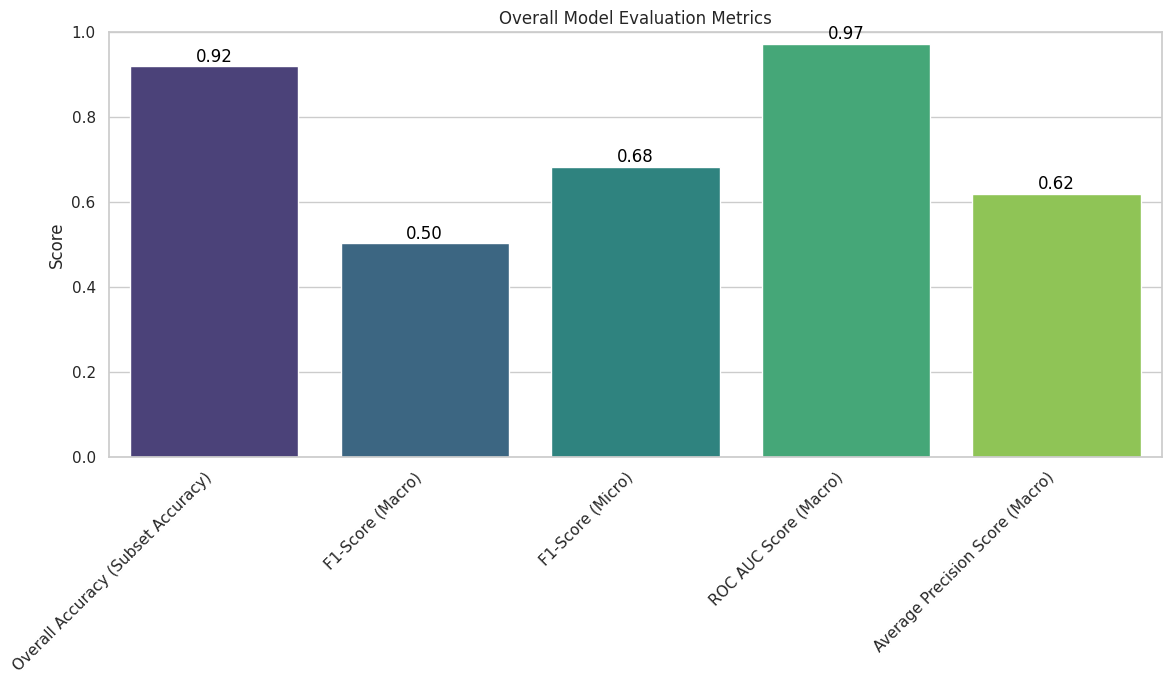

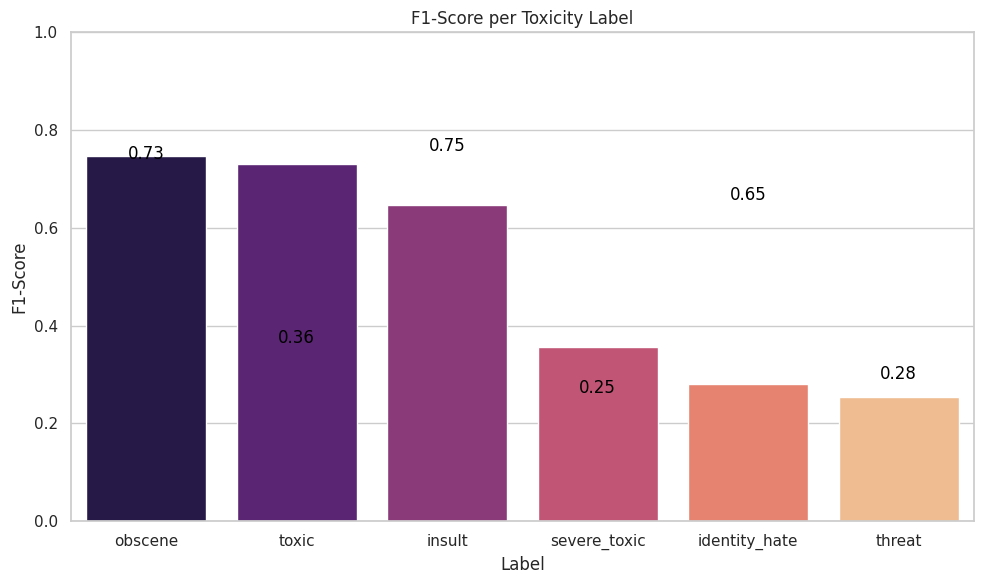

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Plot Overall Evaluation Metrics ---
overall_metrics_names = [
    "Overall Accuracy (Subset Accuracy)",
    "F1-Score (Macro)",
    "F1-Score (Micro)",
    "ROC AUC Score (Macro)",
    "Average Precision Score (Macro)"
]
overall_metrics_values = [
    overall_accuracy,
    f1_macro,
    f1_micro,
    roc_auc_macro,
    avg_precision_macro
]

plt.figure(figsize=(12, 7))
sns.barplot(x=overall_metrics_names, y=overall_metrics_values, hue=overall_metrics_names, palette="viridis", legend=False)
plt.title("Overall Model Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1) # Metrics are usually between 0 and 1
plt.xticks(rotation=45, ha="right")

# Add values on top of the bars
for index, value in enumerate(overall_metrics_values):
    plt.text(index, value + 0.01, f'{value:.2f}', color='black', ha="center")

plt.tight_layout()
plt.show()

# --- Plot F1-Score per Label ---
# The label_cols and individual F1 scores are available from the previous cell output.
# We can extract them into a dictionary or DataFrame for plotting.
f1_scores_per_label = {
    label_cols[0]: 0.7315,
    label_cols[1]: 0.3552,
    label_cols[2]: 0.7477,
    label_cols[3]: 0.2529,
    label_cols[4]: 0.6476,
    label_cols[5]: 0.2810
}

f1_df = pd.DataFrame(list(f1_scores_per_label.items()), columns=['Label', 'F1-Score'])

f1_df = f1_df.sort_values(by='F1-Score', ascending=False) # Sort for better visualization

plt.figure(figsize=(10, 6))
sns.barplot(x='Label', y='F1-Score', data=f1_df, hue='Label', palette="magma", legend=False)
plt.title("F1-Score per Toxicity Label")
plt.ylabel("F1-Score")
plt.ylim(0, 1)

# Add values on top of the bars
for index, row in f1_df.iterrows():
    plt.text(index, row['F1-Score'] + 0.01, f'{row["F1-Score"]:.2f}', color='black', ha="center")

plt.tight_layout()
plt.show()


--- Dynamic Predictions and Scores ---

Sample 1: Original Text: 'You are a horrible idiot!'
  Binary Predictions: {'toxic': 1, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 1, 'identity_hate': 0}
  Prediction Probabilities: {'toxic': np.float64(0.9966790186096522), 'severe_toxic': np.float64(0.009809933462844258), 'obscene': np.float64(0.42377563008658486), 'threat': np.float64(0.002608670089004035), 'insult': np.float64(0.9634699977309302), 'identity_hate': np.float64(0.007651693524186135)}



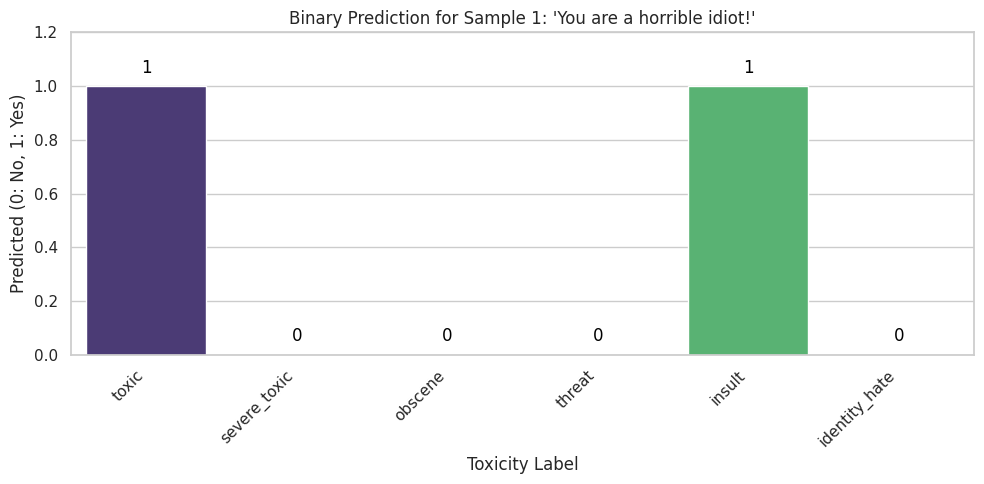

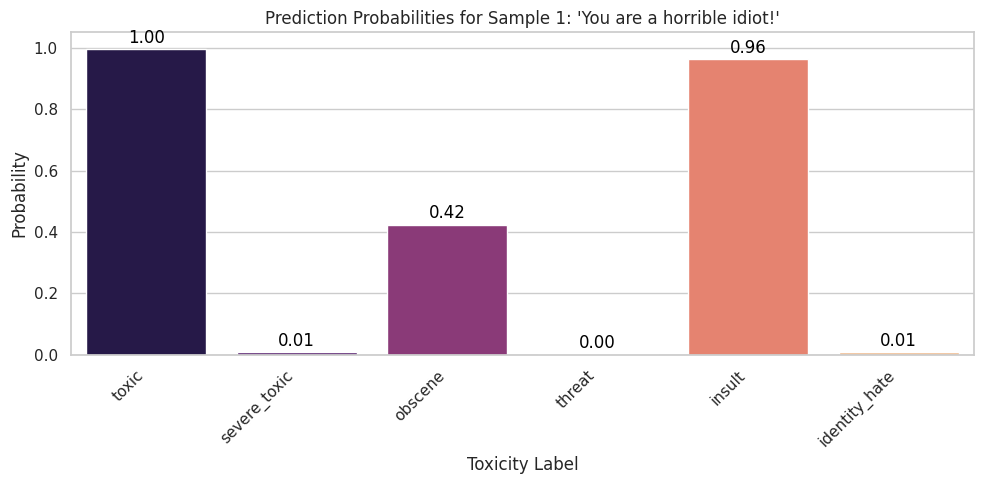

Sample 2: Original Text: 'I love this! Such a beautiful day '
  Binary Predictions: {'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0}
  Prediction Probabilities: {'toxic': np.float64(0.05932831401630693), 'severe_toxic': np.float64(0.003917180816181086), 'obscene': np.float64(0.026554609030153543), 'threat': np.float64(0.0016583062740127537), 'insult': np.float64(0.01914098670294822), 'identity_hate': np.float64(0.007633072974777639)}



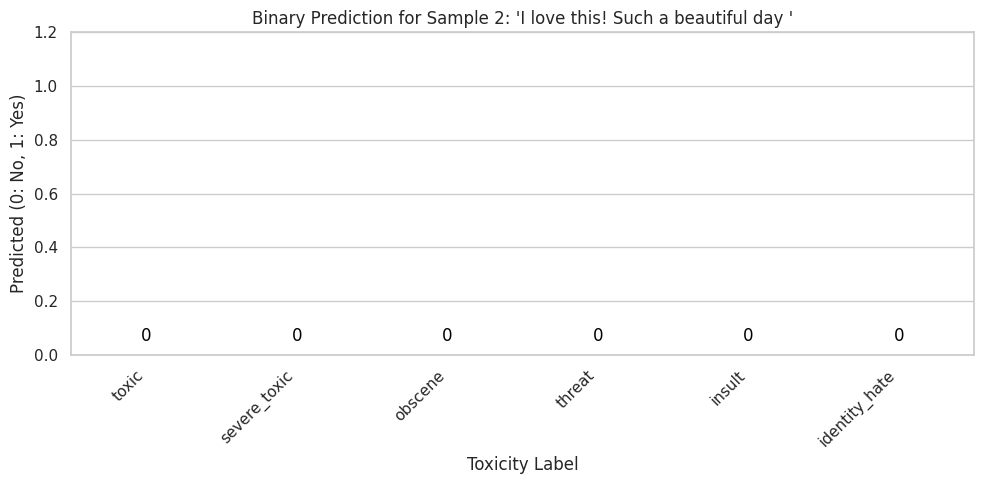

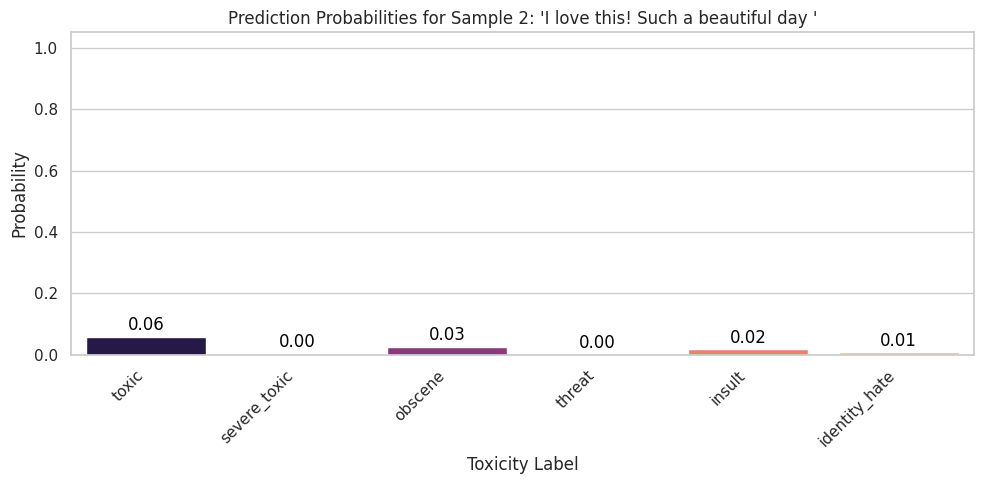

Sample 3: Original Text: 'I will find you and hurt you.'
  Binary Predictions: {'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0}
  Prediction Probabilities: {'toxic': np.float64(0.28000399149006777), 'severe_toxic': np.float64(0.008264092942161686), 'obscene': np.float64(0.04470952533517705), 'threat': np.float64(0.013508762116811854), 'insult': np.float64(0.03746989221756206), 'identity_hate': np.float64(0.004019519388259934)}



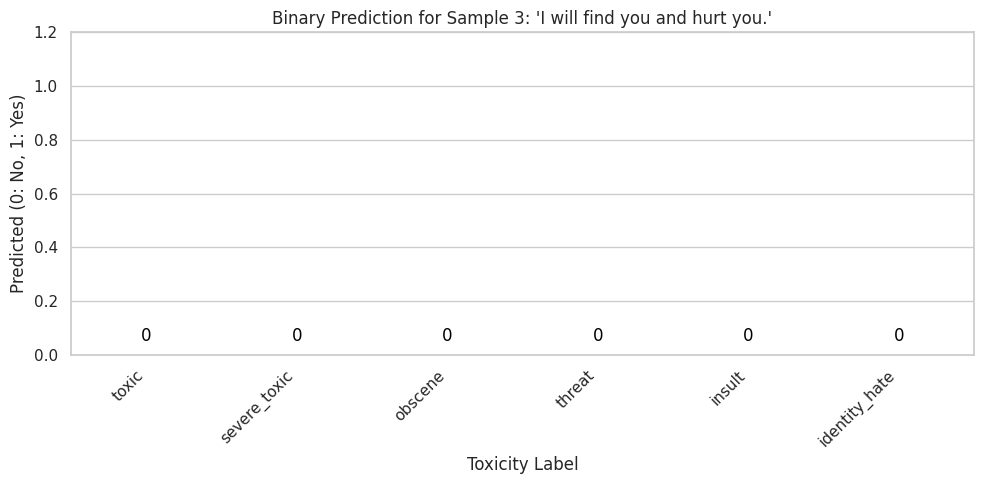

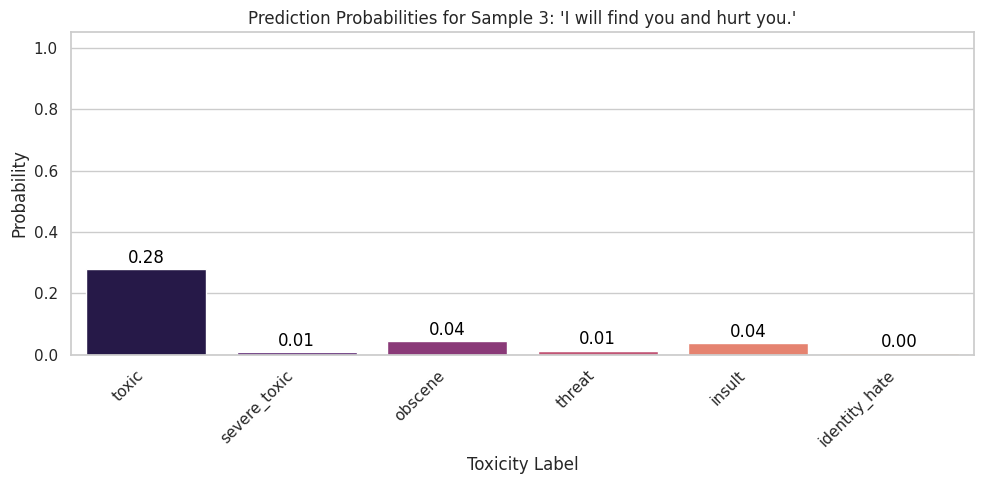

Sample 4: Original Text: 'That was a stupid move, fool!'
  Binary Predictions: {'toxic': 1, 'severe_toxic': 0, 'obscene': 1, 'threat': 0, 'insult': 1, 'identity_hate': 0}
  Prediction Probabilities: {'toxic': np.float64(0.9964380937160165), 'severe_toxic': np.float64(0.009105973829509175), 'obscene': np.float64(0.6791332903256568), 'threat': np.float64(0.005954066683683411), 'insult': np.float64(0.9768785861343259), 'identity_hate': np.float64(0.06394656933417206)}



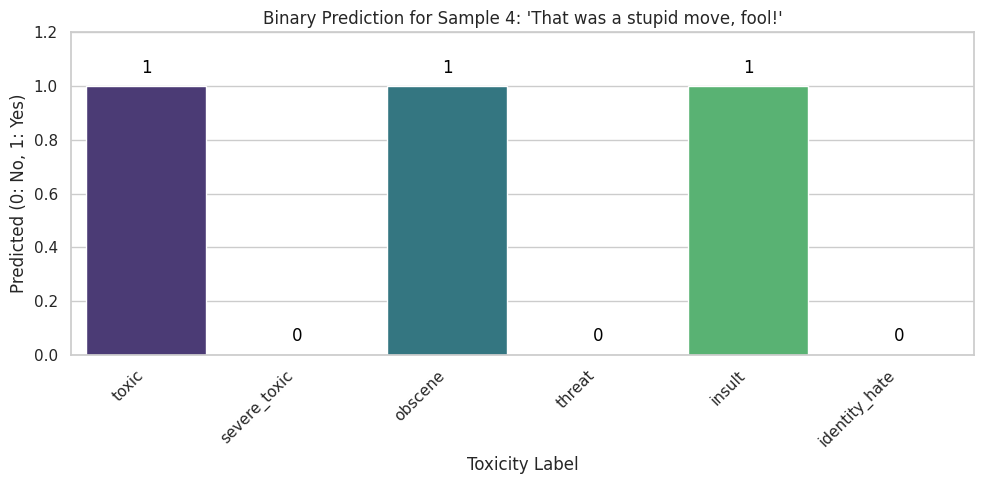

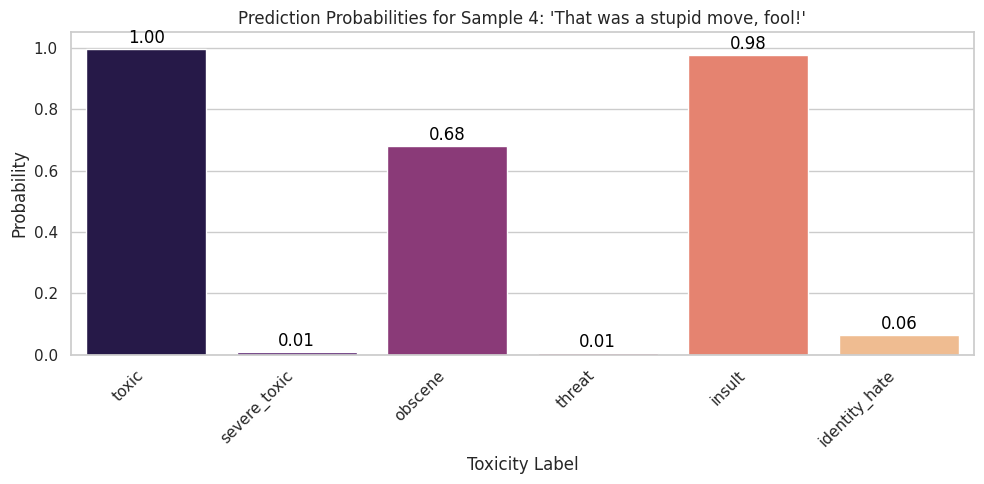

Sample 5: Original Text: 'You are a great person, kind and nice.'
  Binary Predictions: {'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0}
  Prediction Probabilities: {'toxic': np.float64(0.056867885922494275), 'severe_toxic': np.float64(0.003925749831693899), 'obscene': np.float64(0.01636118038640318), 'threat': np.float64(0.0019659786442596345), 'insult': np.float64(0.02303981186935987), 'identity_hate': np.float64(0.00308202488920346)}



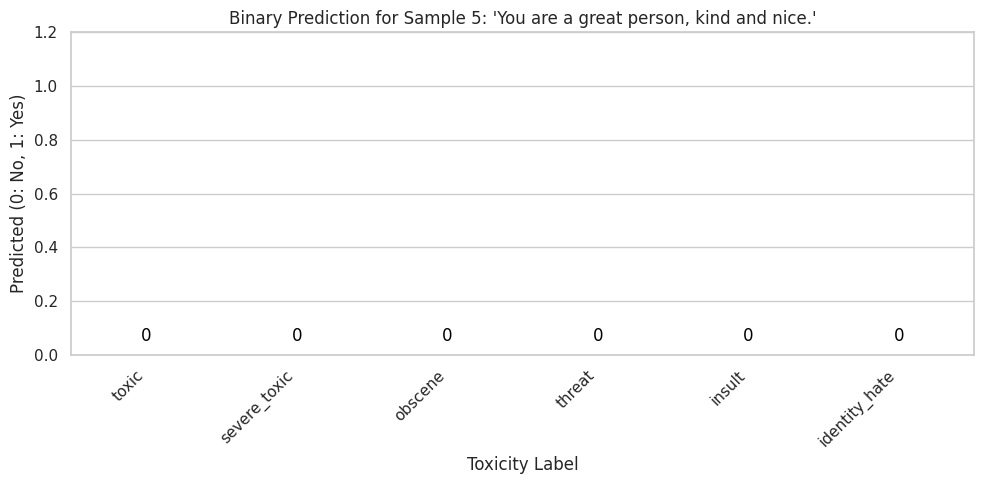

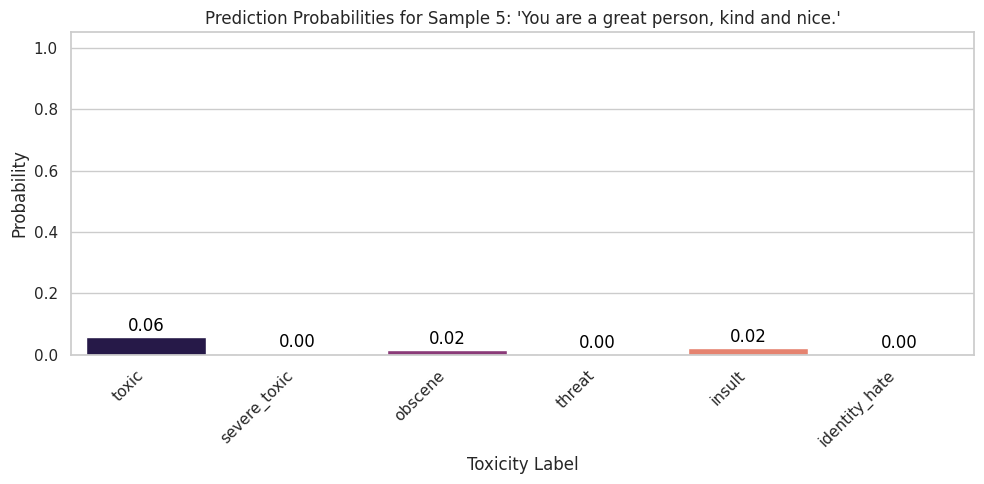

In [18]:
# Prediction Tests

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Example Tests

test_samples = [
    "You are a horrible idiot!",
    "I love this! Such a beautiful day ",
    "I will find you and hurt you.",
    "That was a stupid move, fool!",
    "You are a great person, kind and nice."
]

# Redefine a simple clean_text if it's not present or to ensure consistent preprocessing
# This function should align with the preprocessing applied to the training data
# For simplicity, we are using the components of the 'preprocess' function and subsequent steps.
# If the 'preprocess' function from earlier cells was intended to be used directly,
# it would need to be re-imported or re-defined here if the kernel state reset.

# The preprocess function from cell 84061a19, remove_stopwords from cell 266aa946, and lemmatize_text from bc497a28
# are part of the global scope, so we can reference them directly if the notebook is run top-to-bottom.
# Assuming these functions are available.

def apply_full_preprocessing(text):
    # Apply the preprocess function (lowercasing, emoji, URL, user masking, character filtering)
    processed_text = preprocess(text)
    # Apply stopword removal
    processed_text = remove_stopwords(processed_text)
    # Apply lemmatization
    processed_text = lemmatize_text(processed_text)
    return processed_text

# Apply preprocessing and make predictions
test_clean = [apply_full_preprocessing(t) for t in test_samples]
test_vec = tfidf_vectorizer.transform(test_clean)

# Get both binary predictions and probability scores
preds_binary = classifier.predict(test_vec)
preds_proba = classifier.predict_proba(test_vec)

print("\n--- Dynamic Predictions and Scores ---\n")

# Visualize and print predictions
for i, (text, pred_bin, pred_prob) in enumerate(zip(test_samples, preds_binary, preds_proba)):
    binary_results = {label: int(p) for label, p in zip(label_cols, pred_bin)}
    probability_results = {label: p for label, p in zip(label_cols, pred_prob)}

    print(f"Sample {i+1}: Original Text: '{text}'")
    print(f"  Binary Predictions: {binary_results}")
    print(f"  Prediction Probabilities: {probability_results}\n")

    # Convert predictions to a DataFrame for easier plotting
    pred_df_binary = pd.DataFrame([binary_results])
    pred_df_proba = pd.DataFrame([probability_results])

    # Plot Binary Predictions
    plt.figure(figsize=(10, 5))
    sns.barplot(x=pred_df_binary.columns, y=pred_df_binary.iloc[0], hue=pred_df_binary.columns, palette="viridis", legend=False)
    plt.title(f"Binary Prediction for Sample {i+1}: '{text}'")
    plt.xlabel("Toxicity Label")
    plt.ylabel("Predicted (0: No, 1: Yes)")
    plt.ylim(0, 1.2) # Set y-axis limit to clearly show 0 or 1
    plt.xticks(rotation=45, ha='right')
    for j, value in enumerate(pred_df_binary.iloc[0]):
        plt.text(j, value + 0.05, str(value), color='black', ha="center")
    plt.tight_layout()
    plt.show()

    # Plot Prediction Probabilities
    plt.figure(figsize=(10, 5))
    sns.barplot(x=pred_df_proba.columns, y=pred_df_proba.iloc[0], hue=pred_df_proba.columns, palette="magma", legend=False)
    plt.title(f"Prediction Probabilities for Sample {i+1}: '{text}'")
    plt.xlabel("Toxicity Label")
    plt.ylabel("Probability")
    plt.ylim(0, 1.05) # Probabilities are between 0 and 1
    plt.xticks(rotation=45, ha='right')
    for j, value in enumerate(pred_df_proba.iloc[0]):
        plt.text(j, value + 0.02, f'{value:.2f}', color='black', ha="center")
    plt.tight_layout()
    plt.show()


In [19]:
# Deploy the model
import pickle
import os

# Define paths to save the model and vectorizer
model_path = 'one_vs_rest_logistic_regression_model.pkl'
vectorizer_path = 'tfidf_vectorizer.pkl'

# Save the trained classifier
with open(model_path, 'wb') as f:
    pickle.dump(classifier, f)
print(f"Classifier saved to {model_path}")

# Save the TF-IDF vectorizer
with open(vectorizer_path, 'wb') as f:
    pickle.dump(tfidf_vectorizer, f)
print(f"TF-IDF Vectorizer saved to {vectorizer_path}")



Classifier saved to one_vs_rest_logistic_regression_model.pkl
TF-IDF Vectorizer saved to tfidf_vectorizer.pkl
